John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

Import Packages

In [1]:
# install.packages("tidymodels")
# install.packages('rlang')
# install.packages("ranger")
# install.packages("rpart.plot")
# install.packages("vip")
library(tidyverse)
library(tidymodels)
library(rpart.plot) # for plotting decision tree
library(vip) # for ranking feature importance
# library(ranger) # engine for random forest

# set random seed
set.seed(42)

Warning message:
"package 'tidyverse' was built under R version 4.4.3"
Warning message:
"package 'ggplot2' was built under R version 4.4.3"
Warning message:
"package 'tibble' was built under R version 4.4.3"
Warning message:
"package 'tidyr' was built under R version 4.4.3"
Warning message:
"package 'readr' was built under R version 4.4.3"
Warning message:
"package 'purrr' was built under R version 4.4.3"
Warning message:
"package 'dplyr' was built under R version 4.4.3"
Warning message:
"package 'forcats' was built under R version 4.4.3"
Warning message:
"package 'lubridate' was built under R version 4.4.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()

Load data

In [ ]:
data <- read_csv("data/matching_opportunities.csv") %>%
    drop_na() # drop any row containing at least one NA value

Rows: 709 Columns: 22
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (21): D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_M6, UST, M1_last_UST, M2...
dttm  (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
# Model Inputs
model_columns <- c(
        # "UST", 
        "does_it_match",
        "D_M1_M2", "D_M1_M3", "D_M1_M4", "D_M1_M5", "D_M1_M6",
        "M1_last_UST", "M2_last_UST", "M3_last_UST", "M4_last_UST", "M5_last_UST", "M6_last_UST", # TODO: These are categorical variables, how does this implementation of knn handle those?
        # "time_M1_last_song", "time_M2_last_song", "time_M3_last_song", "time_M4_last_song", "time_M5_last_song", "time_M6_last_song",
    	"time_since_M1_last_song", "time_since_M2_last_song", "time_since_M3_last_song", "time_since_M4_last_song", "time_since_M5_last_song", "time_since_M6_last_song" # did not include time since M1 last song because it is always 0
        # "time_rel_sunrise"
    )

In [4]:
# Set data types and select input columns
data <- data %>% 
    mutate(across(contains("UST"), ~ as.factor(.x)), 
        does_it_match = as.factor(does_it_match),
        number_of_matches = as.integer(number_of_matches)) %>%
    select(model_columns)

Warning message:
"Using an external vector in selections was deprecated in tidyselect 1.1.0.
ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(model_columns)

  # Now:
  data %>% select(all_of(model_columns))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>."


In [5]:
glimpse(data)

Rows: 416
Columns: 18
$ does_it_match           <fct> 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1…
$ D_M1_M2                 <dbl> 94.0368, 94.0368, 94.0368, 94.0368, 94.0368, 9…
$ D_M1_M3                 <dbl> 53.50176, 46.47336, 46.47336, 46.47336, 46.473…
$ D_M1_M4                 <dbl> 61.21936, 61.21936, 61.21936, 61.21936, 61.219…
$ D_M1_M5                 <dbl> 62.95599, 62.95599, 62.95599, 62.95599, 62.955…
$ D_M1_M6                 <dbl> 78.21623, 62.38124, 62.38124, 62.38124, 62.381…
$ M1_last_UST             <fct> 20, 29, 9, 8, 3, 116, 29, 10, 8, 3, 21, 5, 9, …
$ M2_last_UST             <fct> 8, 5, 16, 9, 3, 8, 8, 9, 3, 9, 16, 8, 20, 8, 8…
$ M3_last_UST             <fct> 3, 8, 8, 8, 8, 8, 8, 9, 3, 0, 16, 8, 0, 8, 3, …
$ M4_last_UST             <fct> 9, 3, 3, 8, 9, 9, 9, 10, 10, 3, 0, 16, 0, 0, 8…
$ M5_last_UST             <fct> 8, 0, 8, 0, 0, 10, 10, 8, 8, 20, 20, 0, 0, 12,…
$ M6_last_UST             <fct> 13, 8, 8, 8, 8, 8, 8, 3, 3, 0, 0, 0, 9, 9, 0, …
$ time_since_M1_la

In [6]:

# train test split
train_test_split <- initial_split(data, prop = 0.7, strata=does_it_match)

train_data <- train_test_split %>% training()
test_data <- train_test_split %>% testing()

# In training data, how many song type matches?
train_data %>%
    group_by(does_it_match) %>%
    summarize(n = n()) %>%
    mutate(percent = 100*n/nrow(train_data))

# use v-fold cross validation to assess model accuracy
v <- 5
train_vfold <- vfold_cv(train_data, v=v, strata = does_it_match)

does_it_match,n,percent
<fct>,<int>,<dbl>
0,188,64.82759
1,102,35.17241


In [7]:
# Data preprocessing using a recipe
recipe <- recipe(does_it_match ~ ., data = train_data) %>%
    step_scale(all_numeric()) %>% # scale all numeric predictors
    step_center(all_numeric()) # center all numeric predictors

In [8]:
# Create model specification
model_tuning_spec <- rand_forest(mtry = tune(), trees = 1000, min_n=tune()) %>%
    set_engine("ranger", importance = "impurity") %>% # importance = impurity measures feature importance (using gini impurity reduction), used for vip() later
    set_mode("classification")

In [9]:
tune_grid <- tidyr::crossing(
    mtry = c(2, 4, 6, 8), # The number of variables randomly sampled as candidates at each split
    min_n = c(2, 5, 10, 15, 20) # Minimum number of data points in a node required for a split
)
eval_metrics <- metric_set(accuracy, precision, recall)

model_tuning <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_tuning_spec) %>%

        tune_grid(resamples = train_vfold, grid=tune_grid, metrics = eval_metrics) # for v-fold cross validation, tuning k parameter
        # fit(data = train_data) # to train on whole train set with no validation set

model_tuning

Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
ERROR while rich displaying an object: Error in (function (..., row.names = NULL, check.rows = FALSE, check.names = TRUE, : arguments imply differing number of rows: 231, 232, 233

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")


In [10]:
# Accuracies listed use 5-fold cross validation 2025-10-17
model_tuning_accuracies <- model_tuning %>% collect_metrics() %>% arrange(.metric) #  %>% filter(.metric == "accuracy")
model_tuning_accuracies

mtry,min_n,.metric,.estimator,mean,n,std_err,.config
<dbl>,<dbl>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
2,2,accuracy,binary,0.6582423,5,0.019010637,pre0_mod01_post0
2,5,accuracy,binary,0.6687082,5,0.010413931,pre0_mod02_post0
2,10,accuracy,binary,0.6616301,5,0.017996699,pre0_mod03_post0
2,15,accuracy,binary,0.6719185,5,0.019311064,pre0_mod04_post0
2,20,accuracy,binary,0.6651973,5,0.018198200,pre0_mod05_post0
4,2,accuracy,binary,0.6682303,5,0.029082558,pre0_mod06_post0
4,5,accuracy,binary,0.6646631,5,0.028515484,pre0_mod07_post0
4,10,accuracy,binary,0.6543162,5,0.030227052,pre0_mod08_post0
4,15,accuracy,binary,0.6577061,5,0.031068475,pre0_mod09_post0


[1] "Best hyperparameters:"
20 
 2 


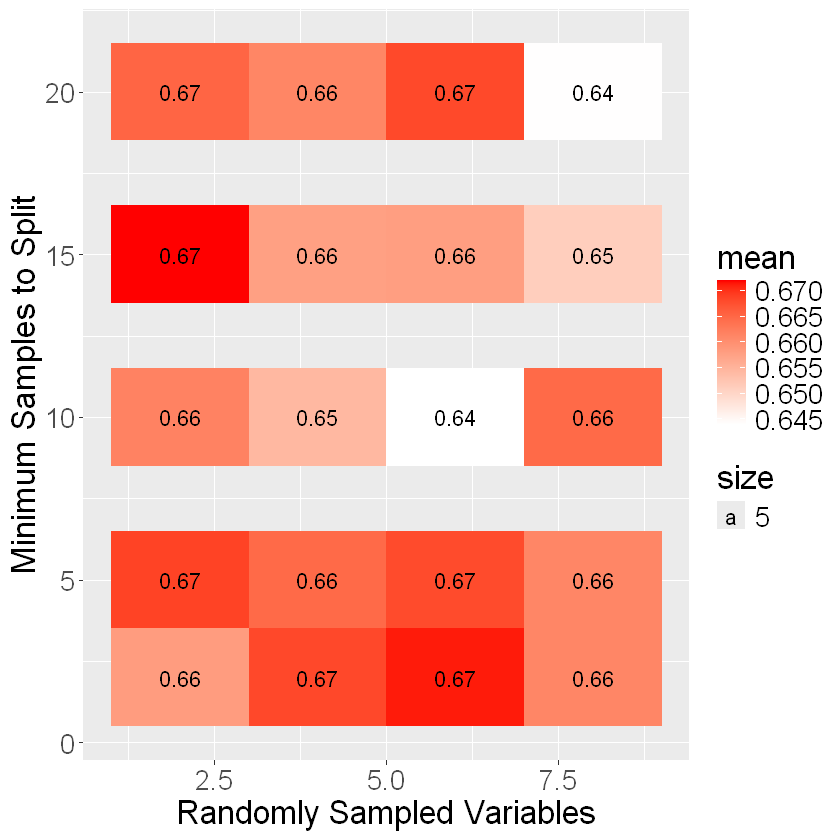

In [11]:
# plot accuracies of all values of hyperparameters

ggplot(model_tuning_accuracies %>% filter(.metric == "accuracy")) +
    geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
    geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
    labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Accuracy", main="Accuracy") +
    theme(text = element_text(size=20)) +
    scale_fill_gradient(low="white", high="red")

# Print best hyperparameter values
best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
print("Best hyperparameters:")
print(best_params)

[1] "Best hyperparameters: (mtry, min_n)"
20 
 2 


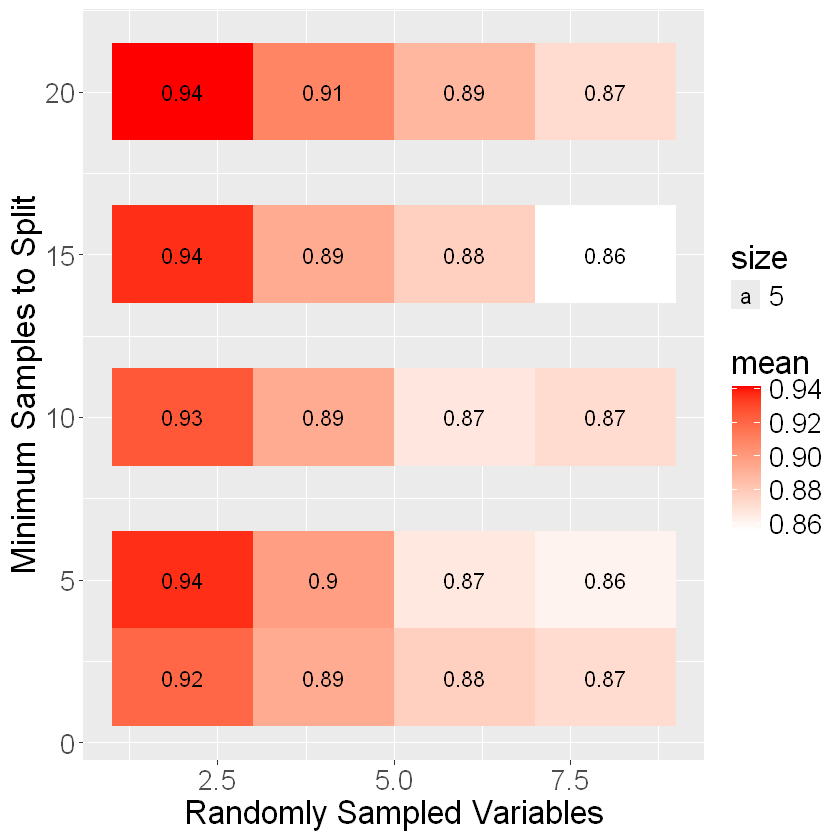

In [12]:
# plot RECALL of all values of hyperparameters

ggplot(model_tuning_accuracies %>% filter(.metric == "recall")) +
    geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
    geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
    labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Recall", main="Recall") +
    theme(text = element_text(size=20)) +
    scale_fill_gradient(low="white", high="red")

# Print best hyperparameter values
best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
print("Best hyperparameters: (mtry, min_n)")
print(best_params)

In [13]:
# retrain model on best parameters
best_params <- model_tuning %>%
  select_best()
print("Best Parameters:")
print(best_params)

model <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_tuning_spec) %>%
    finalize_workflow(best_params) %>%
    # fit_resamples(resamples = train_vfold) # for v-fold cross validation
    fit(data = train_data) # to train on whole train set with no validation set

model

Warning message in select_best(.):
"No value of `metric` was given; "accuracy" will be used."


[1] "Best Parameters:"
# A tibble: 1 × 3
   mtry min_n .config         
  <dbl> <dbl> <chr>           
1     2    15 pre0_mod04_post0


══ Workflow [trained] ══════════════════════════════════════════════════════════
Preprocessor: Recipe
Model: rand_forest()

── Preprocessor ────────────────────────────────────────────────────────────────
2 Recipe Steps

• step_scale()
• step_center()

── Model ───────────────────────────────────────────────────────────────────────
Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, mtry = min_cols(~2,      x), num.trees = ~1000, min.node.size = min_rows(~15, x),      importance = ~"impurity", num.threads = 1, verbose = FALSE,      seed = sample.int(10^5, 1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  1000 
Sample size:                      290 
Number of independent variables:  17 
Mtry:                             2 
Target node size:                 15 
Variable importance mode:         impurity 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.208783 

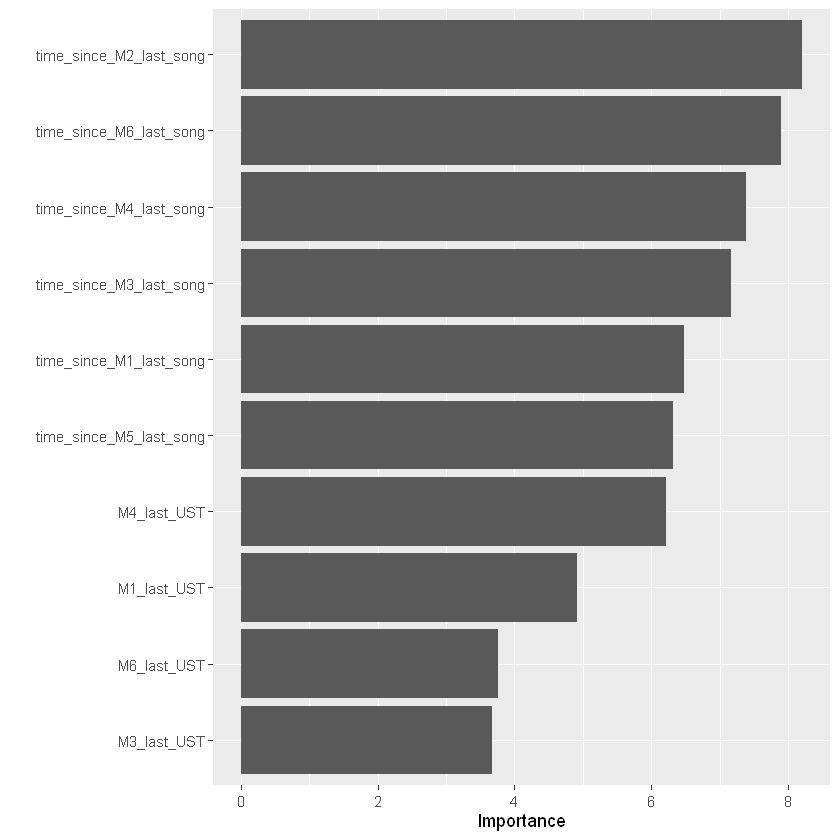

In [14]:
model %>% extract_fit_engine() %>% vip(num_features=10)

In [15]:
# Predict on the test set, and create a new DataFrame with inputs and outputs
test_predictions <- model %>% predict(test_data) %>%
    bind_cols(test_data)

In [16]:
# test_predictions

In [17]:
# What was the accuracy, precision, and recall of our model?
test_predictions %>% metrics(truth = does_it_match, estimate = .pred_class)
test_predictions %>% precision(truth = does_it_match, estimate = .pred_class, event_level = "second") # Precision = correct positive predictions / total positive predictions
test_predictions %>% recall(truth = does_it_match, estimate = .pred_class, event_level = "second") # Recall = correct positive predictions / total positive test set observations

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
accuracy,binary,0.6349206
kap,binary,0.0878187


.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
precision,binary,0.4736842


.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
recall,binary,0.2


In [18]:
# test_predictions %>% pull(does_it_match) %>% levels()
confusion_matrix <- test_predictions %>%
    conf_mat(truth = does_it_match, estimate = .pred_class)
confusion_matrix

          Truth
Prediction  0  1
         0 71 36
         1 10  9